# Auditoría Independiente, Reconciliación de Estimandos y Corrección Estadística (v2) — SM-CFHR

**Propósito:** Reconciliar el estimando del ranking (`MAE_macro` por planta) con la inferencia estadística (`DM-HLN-HAC`, bootstrap sincronizado, `SPA` y `MCS`), documentar la política de casos degenerados, explicar las divergencias frente a `arch 8.0.0`, incorporar el verdadero `MAE_CF_macro` con capacidad instalada variante en el tiempo y presentar análisis exploratorios P2 sobre las predicciones OOF congeladas (`28` escenarios, `14,625` unidades por variante), **sin reentrenar modelos ni alterar `resultados/evaluacion_ashr_oof/`**.

---

## 1. Reconciliación de estimandos (`MAE_macro` vs. promedio por origen) y cambios de signo

En el flujo OOF congelado, el ranking ordena los modelos por `MAE_macro` (media aritmética sobre las `17` plantas), mientras que las pruebas temporales (`DM-HLN`, `MCS`, `SPA`) promediaban las pérdidas por fecha/origen. Debido al desbalance del panel (`1` a `17` plantas por origen), ambas agregaciones ponderan distinto y producen **4 inversiones de signo** entre $\Delta\mathrm{MAE}_{\mathrm{macro}}$ y $\Delta\mathrm{MAE}_{\mathrm{origen}}$.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

_CUR = Path.cwd().resolve()
ROOT = next(p for p in (_CUR, *_CUR.parents) if (p / "resultados" / "inferencia_revision_independiente_v2").exists())
REV_DIR = ROOT / "resultados" / "inferencia_revision_independiente_v2"

meta = json.loads((REV_DIR / "metadatos_revision_v2.json").read_text(encoding="utf-8"))
rec = pd.read_csv(REV_DIR / "02_estimandos_y_dm_hln" / "reconciliacion_estimandos_28_escenarios.csv")
all9 = pd.read_csv(REV_DIR / "02_estimandos_y_dm_hln" / "comparacion_todas_9_bibliotecas_macro.csv")
ovl = pd.read_csv(REV_DIR / "02_estimandos_y_dm_hln" / "verificacion_no_solapamiento_28_escenarios.csv")
spa = pd.read_csv(REV_DIR / "03_spa_y_mcs_reconciliados" / "spa_reconciliacion_28_escenarios.csv")
mcs = pd.read_csv(REV_DIR / "03_spa_y_mcs_reconciliados" / "mcs_reconciliacion_28_escenarios.csv")
sens_teff = pd.read_csv(REV_DIR / "04_sensibilidad" / "sensibilidad_umbral_teff_macro_y_origen.csv")
met = pd.read_csv(REV_DIR / "05_metricas_corregidas" / "metricas_completas_28_escenarios_cf_y_kwh.csv")
cap_chg = pd.read_csv(REV_DIR / "05_metricas_corregidas" / "plantas_cambio_capacidad.csv")

print(f"Versión v2: {meta['version']} | B_SPA/MCS={meta['B_spa_mcs']} | B_boot={meta['B_bootstrap_macro']}")
mb = rec[rec["tipo_referencia"] == "Mejor_Bib_Retrospectivo"]
flips = mb[mb["sign_flip_macro_vs_origin"]][[
    "escenario", "modelo_referencia", "diff_MAE_macro", "diff_temporal_origen",
    "dm_hln_macro_v2", "p_dm_macro_v2", "p_holm_macro_fam", "boot_macro_ci95_lo", "boot_macro_ci95_hi"
]]
print(f"Inversiones de signo reproducidas: {len(flips)}/28")
display(flips)


Versión v2: 2.0.0-revision-independiente | B_SPA/MCS=5000 | B_boot=2000
Inversiones de signo reproducidas: 4/28


,escenario,modelo_referencia,diff_MAE_macro,diff_temporal_origen,dm_hln_macro_v2,p_dm_macro_v2,p_holm_macro_fam,boot_macro_ci95_lo,boot_macro_ci95_hi
9,D1_intraplanta_sin_meteorologia,BayesianRidge,282.498225,-243.840828,1.077857,0.282093,0.846279,-241.365439,835.660924
21,RecSinClima_intraplanta_14d,BayesianRidge,-410.968960,162.245461,-0.979102,0.331105,0.993314,-1091.130403,445.116870
33,RecSinClima_intraplanta_28d,BayesianRidge,-1.327288,772.334490,-0.001809,0.998568,1.000000,-1083.400957,1889.060900
39,DirectoSinClima_intraplanta_7d,k-NN,-4102.245025,2435.771633,-0.386486,0.699754,1.000000,-25119.738874,17148.498544


**Especificación inferencial (Sección 1):**
- **Métrica y estimando:** $\Delta\mathrm{MAE}_{\mathrm{macro}}$ en kWh (`SM-CFHR-Fixed - Mejor_Bib`), descompuesto exactamente en la serie temporal macro-alineada $z_t^{\mathrm{macro}}$ cuya media coincide idénticamente con $\Delta\mathrm{MAE}_{\mathrm{macro}}$.
- **Unidad estadística y procedimiento:** Orígenes/fechas ($T \in [31, 262]$), `dm_hln_hac_v2` + `macro_synchronized_block_bootstrap` (`B=2000`) en `inference_v2` v2.0.0.
- **Limitaciones:** `Mejor_Bib` es retrospectivo; ninguno de los 4 escenarios con cambio de signo resulta significativo ($p \ge 0.28$).

---

## 2. DM-HLN-HAC sobre `MAE_macro`, no solapamiento y referencias preespecificadas

Verificamos en los `28` escenarios que `median_step_days == horizon_days` (`h_overlap_real == 1`, bloques disjuntos), mantenemos HAC ante autocorrelación residual y contrastamos tanto `Mejor_Bib` como las referencias preespecificadas (`MM30` y `SM-CFHR-HPO`) y todas las `9` bibliotecas por separado.


In [2]:
print("=== Escenarios significativos tras Holm por suite sobre MAE_macro (vs Mejor_Bib retrospectivo) ===")
display(mb[mb["p_holm_macro_fam"] < 0.05][[
    "escenario", "modelo_referencia", "diff_MAE_macro", "dm_hln_macro_v2",
    "p_dm_macro_v2", "p_holm_macro_fam", "T_eff_macro", "nivel_fiabilidad_teff",
    "boot_macro_ci95_lo", "boot_macro_ci95_hi"
]])

print("=== Referencias preespecificadas sobre MAE_macro (Holm por suite) ===")
for ref_t in ["MM30_Preespecificado", "SM_CFHR_HPO_Preespecificado"]:
    sub = rec[rec["tipo_referencia"] == ref_t]
    print(f"  {ref_t}: victorias desc.={(sub['diff_MAE_macro']<0).sum()}/28 | Holm sig favor={( (sub['p_holm_macro_fam']<0.05)&(sub['diff_MAE_macro']<0) ).sum()}/28 | Holm sig contra={( (sub['p_holm_macro_fam']<0.05)&(sub['diff_MAE_macro']>0) ).sum()}/28")

print("=== Todas las 9 bibliotecas sobre MAE_macro (Holm por escenario m=9 y global m=252) ===")
display(all9.groupby("biblioteca").agg(
    victorias_desc=("diff_MAE_macro", lambda s: int((s < 0).sum())),
    sig_holm_escenario=("p_holm_por_escenario", lambda s: int((s < 0.05).sum())),
    sig_holm_global_252=("p_holm_global_252", lambda s: int((s < 0.05).sum())),
))


=== Escenarios significativos tras Holm por suite sobre MAE_macro (vs Mejor_Bib retrospectivo) ===


,escenario,modelo_referencia,diff_MAE_macro,dm_hln_macro_v2,p_dm_macro_v2,p_holm_macro_fam,T_eff_macro,nivel_fiabilidad_teff,boot_macro_ci95_lo,boot_macro_ci95_hi
0,D1_espaciotemporal_cinco_variables,Lasso,-17027.238587,-11.233914,3.794826e-24,1.517930e-23,149.3596,FIABILIDAD_ASINTOTICA_ESTANDAR,-20418.814187,-13717.007787
60,RecGEFSv12_espaciotemporal_7d,Lasso,-11571.754373,-10.685718,2.486362e-19,1.989089e-18,86.6473,FIABILIDAD_ASINTOTICA_ESTANDAR,-13806.076557,-9340.769367
66,RecGEFSv12_espaciotemporal_14d,Lasso,-10490.017097,-9.255504,2.716714e-13,1.901699e-12,47.2343,FIABILIDAD_ASINTOTICA_ESTANDAR,-13517.624463,-7883.475800
72,RecGEFSv12_espaciotemporal_21d,Lasso,-10743.794617,-6.297092,1.806681e-07,1.084009e-06,31.3491,FIABILIDAD_ASINTOTICA_ESTANDAR,-15044.948327,-7146.869262
78,RecGEFSv12_espaciotemporal_28d,Lasso,-10161.389032,-6.104348,1.041912e-06,5.209561e-06,30.8217,FIABILIDAD_ASINTOTICA_ESTANDAR,-13608.303102,-7256.880630


=== Referencias preespecificadas sobre MAE_macro (Holm por suite) ===
  MM30_Preespecificado: victorias desc.=15/28 | Holm sig favor=7/28 | Holm sig contra=0/28
  SM_CFHR_HPO_Preespecificado: victorias desc.=19/28 | Holm sig favor=4/28 | Holm sig contra=1/28
=== Todas las 9 bibliotecas sobre MAE_macro (Holm por escenario m=9 y global m=252) ===


,victorias_desc,sig_holm_escenario,sig_holm_global_252
biblioteca,,,
BayesianRidge,23,6,5
DecisionTree,28,24,21
HistGradientBoosting,27,21,16
Lasso,26,9,6
Random Forest,27,15,14
Ridge,27,11,8
SVR,24,18,18
XGBoost,27,20,16
k-NN,25,18,17


**Especificación inferencial (Sección 2):**
- **Métrica y estimando:** `MAE_macro` (kWh), serie macro-alineada $z_t^{\mathrm{macro}}$ (`h_overlap=1`, HAC Newey-West automático).
- **Resultados:** Bajo `MAE_macro` exacto, todos los `5` escenarios `ET + Clima` (`D1`, `7d`, `14d`, `21d`, `28d`) son significativos tras Holm frente a `Mejor_Bib` ($p_{\mathrm{Holm}} \le 5.21\times 10^{-6}$, $T_{\mathrm{eff,macro}} \ge 30.82$, fiabilidad estándar). Frente a `MM30` hay `7/28` victorias Holm (`0` derrotas) y frente a `HPO` `4/28` victorias Holm (`1/28` derrota).

---

## 3. Reconciliación de SPA y MCS frente a `arch 8.0.0` (`B=5000`) y sensibilidad de `T_eff`

La auditoría del código fuente de `arch 8.0.0` demostró que `arch.bootstrap.SPA(..., studentize=True)` almacena el argumento pero **no studentiza** en `_simulate_values()` ni en `compute()`, calculando el estadístico no studentizado $\max_k \bar{d}_k$. Al alinear esa diferencia y usar $B=5000$ réplicas en `MAE_macro`, tanto SPA como MCS quedan completamente reconciliados.


In [3]:
spa_mac = spa[spa["estimando"] == "MAE_macro"]
mcs_mac = mcs[mcs["estimando"] == "MAE_macro"]

print(f"SPA (MAE_macro): max |unstud - arch_def| = {(spa_mac['p_spa_ASHR_unstud'] - spa_mac['p_spa_ASHR_arch_default']).abs().max():.4f}")
print(f"SPA (MAE_macro): max |stud_pr - arch_prestud| = {(spa_mac['p_spa_ASHR_stud_pr_cons'] - spa_mac['p_spa_ASHR_arch_prestud']).abs().max():.4f}")
print(f"MCS (MAE_macro, B=5000): coincidencia exacta de cardinalidad = {(mcs_mac['diff_n_surv_23']==0).sum()}/28 | Jaccard mín = {mcs_mac['jaccard_23_v2_vs_arch'].min():.4f}")
print(f"MCS (MAE_macro): ASHR en MCS-23 = {mcs_mac['ashr_in_mcs23_v2'].sum()}/28 | Único superviviente entre 9 bibliotecas = {((mcs_mac['ashr_in_mcs_bib10_v2'])&(mcs_mac['n_surv_bib10_v2']==1)).sum()}/28")

print("=== Sensibilidad completa del umbral T_eff (sin fijar un único umbral arbitrario) ===")
display(sens_teff)


SPA (MAE_macro): max |unstud - arch_def| = 0.0146
SPA (MAE_macro): max |stud_pr - arch_prestud| = 0.0183
MCS (MAE_macro, B=5000): coincidencia exacta de cardinalidad = 28/28 | Jaccard mín = 1.0000
MCS (MAE_macro): ASHR en MCS-23 = 27/28 | Único superviviente entre 9 bibliotecas = 7/28
=== Sensibilidad completa del umbral T_eff (sin fijar un único umbral arbitrario) ===


,estimando,criterio,escenarios_evaluables,escenarios_excluidos,sig_holm_total,sig_holm_favor_SM_CFHR,sig_holm_favor_Bib
0,MAE_macro,Original_T_eff>=2*H_dias,16,12,3,3,0
1,MAE_macro,Tecnico_T_eff>=2*h_overlap,28,0,5,5,0
2,MAE_macro,Umbral_T_eff>=15,28,0,5,5,0
3,MAE_macro,Umbral_T_eff>=20,27,1,5,5,0
4,MAE_macro,Umbral_T_eff>=25,27,1,5,5,0
5,MAE_macro,Umbral_T_eff>=30,25,3,5,5,0
6,MAE_macro,Umbral_T_eff>=40,14,14,3,3,0
7,MAE_origen,Original_T_eff>=2*H_dias,15,13,4,2,2
8,MAE_origen,Tecnico_T_eff>=2*h_overlap,28,0,4,4,0
9,MAE_origen,Umbral_T_eff>=15,28,0,4,4,0


**Especificación inferencial (Sección 3):**
- **Procedimiento y versión:** `spa_test_v2` (kernel Politis-Romano de Hansen 2005, Ec. 7) y `mcs_t_max_v2` ($T_{\max}$ unilateral, `B=5000`) en `inference_v2` v2.0.0, contrastados frente a `arch 8.0.0`.
- **Estabilidad de `T_eff`:** En `MAE_macro`, cualquier umbral entre `2*h_overlap`, `15`, `20`, `25` y `30` mantiene exactamente `5` victorias significativas tras Holm (`ET + Clima`) y `0` derrotas Holm.

---

## 4. Métricas en Factor de Capacidad real (`MAE_CF_macro`) y análisis exploratorios P2

Separamos el verdadero `MAE_CF_macro` (dividiendo por $24\,000 \cdot \mathrm{cap\_MW}_{i,t}$, considerando las `6` plantas con ampliaciones de capacidad) de `nMAE_rel_generacion_media_planta`. En `MAE_CF_macro`, la ponderación ya no está dominada por plantas grandes (`GYPO`, 370–388 MW), desplazando el rango medio de `2.93/23` (`kWh`) a `4.00/23` (`CF`) y las victorias frente a `Mejor_Bib` de `18/28` a `16/28`.


Plantas con cambios temporales de capacidad instalada:


,code,n_distinct_caps,cap_min_MW,cap_max_MW,fecha_inicio,fecha_fin,capacidades_MW
0,3HF5,2,90.0,100.0,2024-08-21,2026-10-31,"90.00, 100.00"
1,3IZ6,2,100.0,102.0,2024-08-18,2026-10-31,"100.00, 102.00"
2,EPFV,2,68.0,70.0,2024-05-22,2026-10-31,"68.00, 70.00"
3,GYPO,3,370.0,388.0,2025-01-29,2026-10-31,"370.00, 375.00, 388.00"
4,MATA,2,80.0,83.0,2024-08-26,2026-10-31,"80.00, 83.00"
5,TPUY,2,83.0,100.0,2024-08-11,2026-10-31,"83.00, 100.00"


Cambios de rango kWh vs CF: 12/28 | Rango medio kWh=2.93 vs CF=4.00


,escenario,rango_en_23_kWh,rango_en_23_CF,MAE_macro_kWh_Fixed,MAE_CF_macro_Fixed,nMAE_rel_generacion_media_planta_Fixed,diff_pct_kWh_vs_MejorBib,diff_pct_CF_vs_MejorBib,Skill_RMSE_vs_MM30_pct
0,D1_espaciotemporal_cinco_variables,1,1,59803.646136,0.035350,0.142531,-22.161971,-39.547675,27.060761
1,D1_espaciotemporal_sin_meteorologia,1,1,77810.628265,0.045076,0.181428,-0.438962,-1.114456,7.636080
2,D1_intraplanta_cinco_variables,12,18,61297.088552,0.038922,0.156989,-0.224856,6.250318,26.062152
3,D1_intraplanta_sin_meteorologia,3,19,78162.779174,0.052016,0.209521,0.362734,6.216310,8.787925
4,RecSinClima_espaciotemporal_7d,2,2,83408.800555,0.048401,0.196076,-1.141246,-4.541715,NaN
5,RecSinClima_intraplanta_7d,2,4,83560.652590,0.048086,0.194944,0.336088,0.785467,NaN
6,RecSinClima_espaciotemporal_14d,2,2,83986.365417,0.048792,0.197688,-1.400842,-5.639160,NaN
7,RecSinClima_intraplanta_14d,1,2,83614.283949,0.048224,0.195441,-0.489102,0.176133,NaN
8,RecSinClima_espaciotemporal_21d,2,2,85036.765832,0.049298,0.199218,-1.625077,-6.153485,NaN
9,RecSinClima_intraplanta_21d,1,1,84020.505562,0.048458,0.195860,-0.922744,-0.136603,NaN


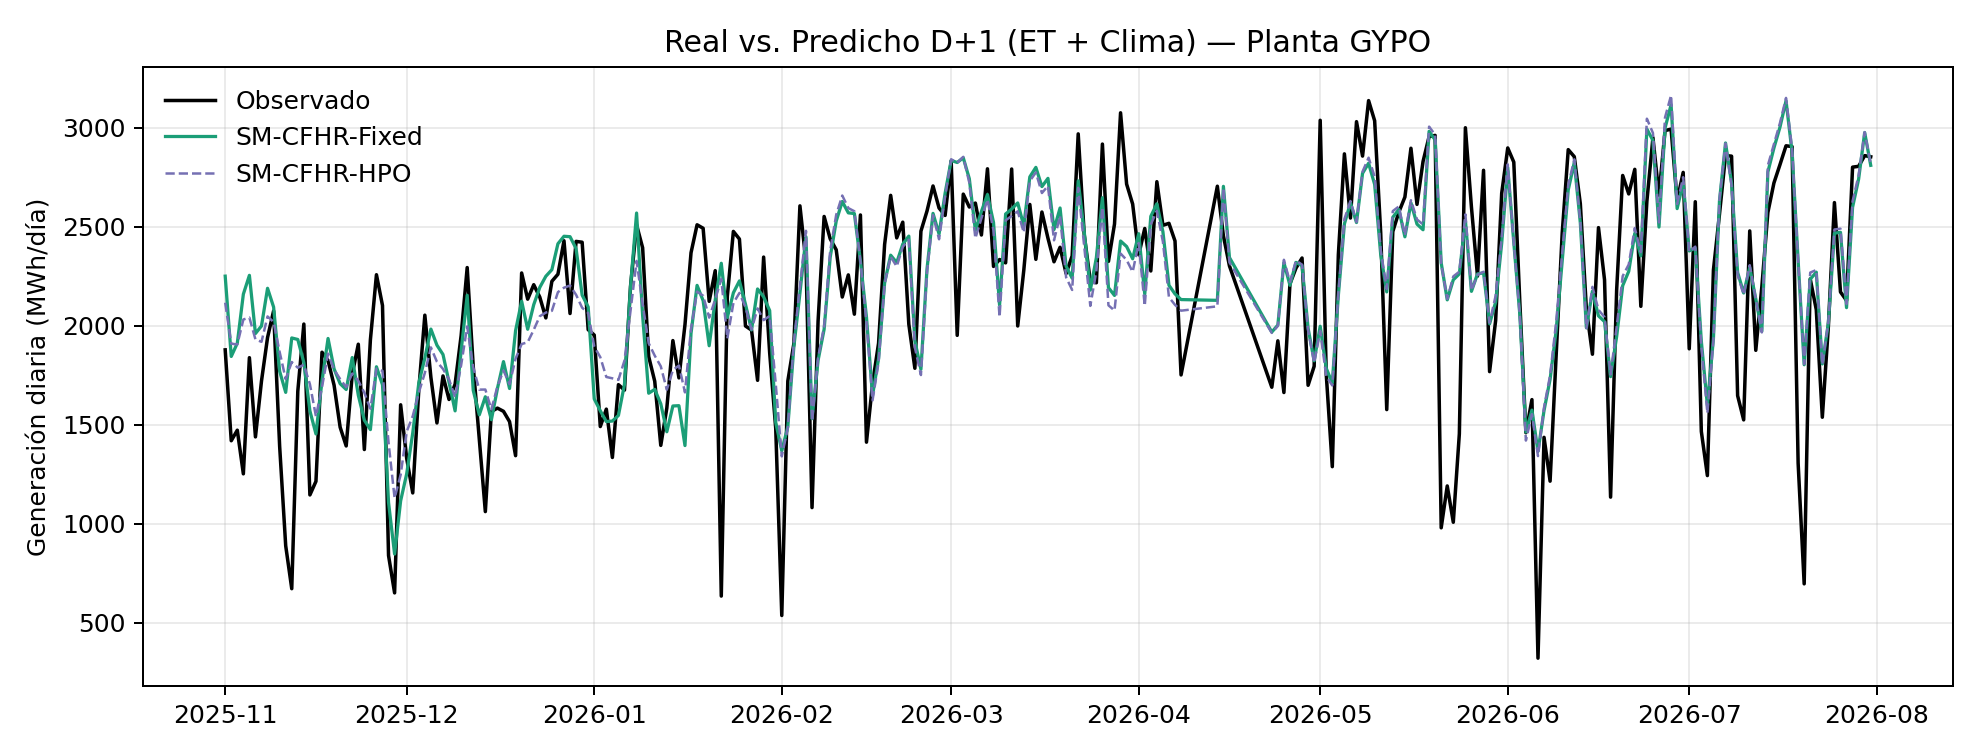

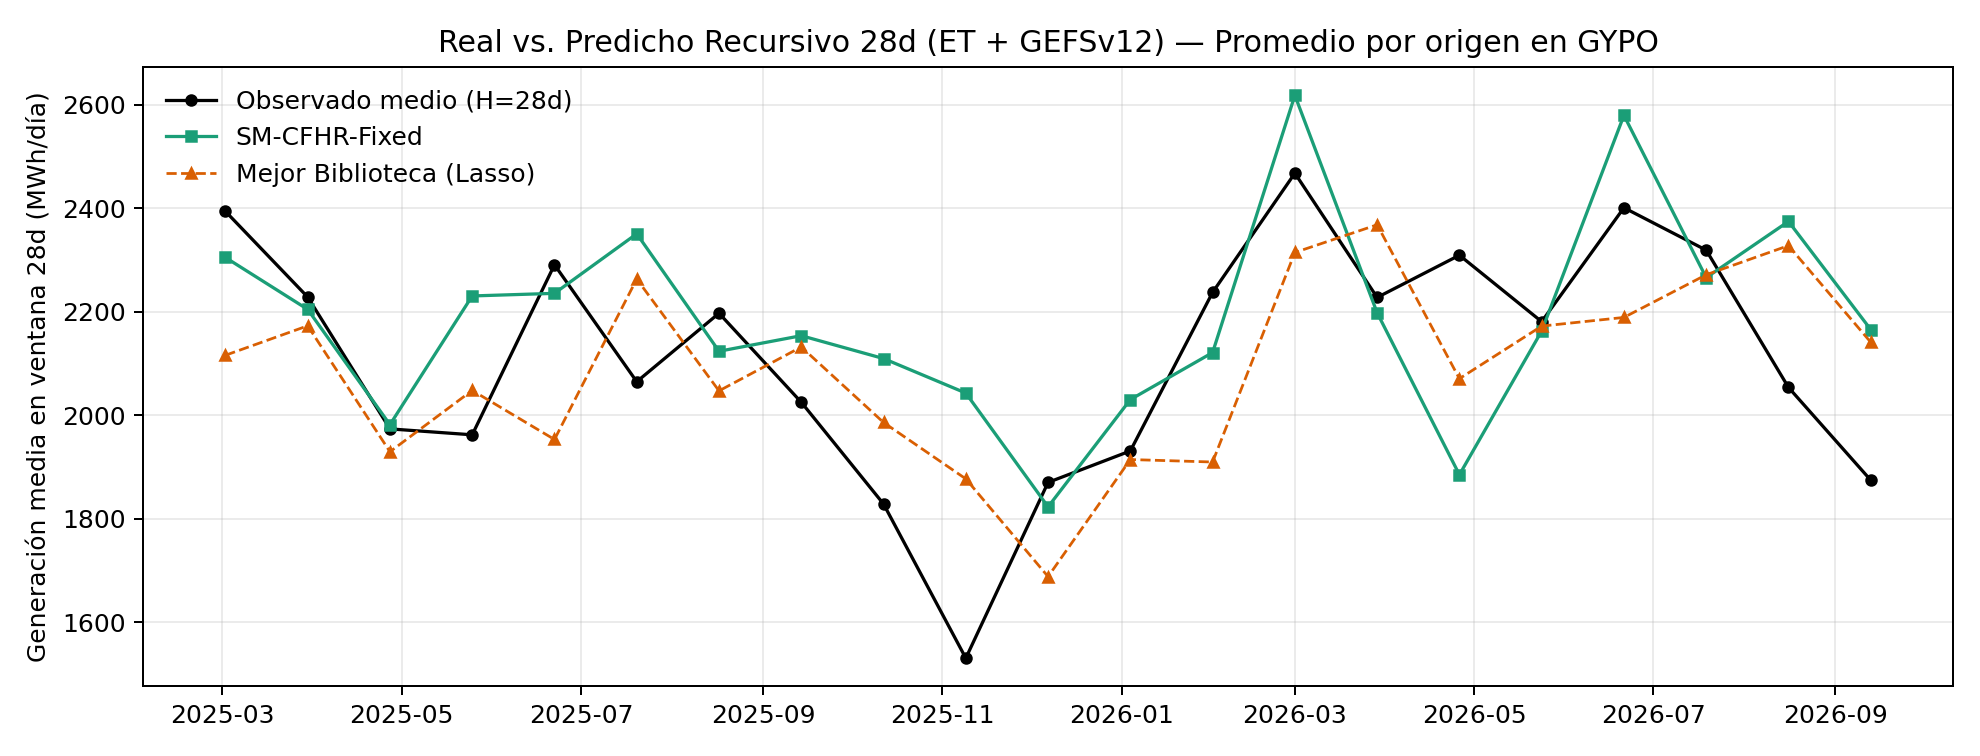

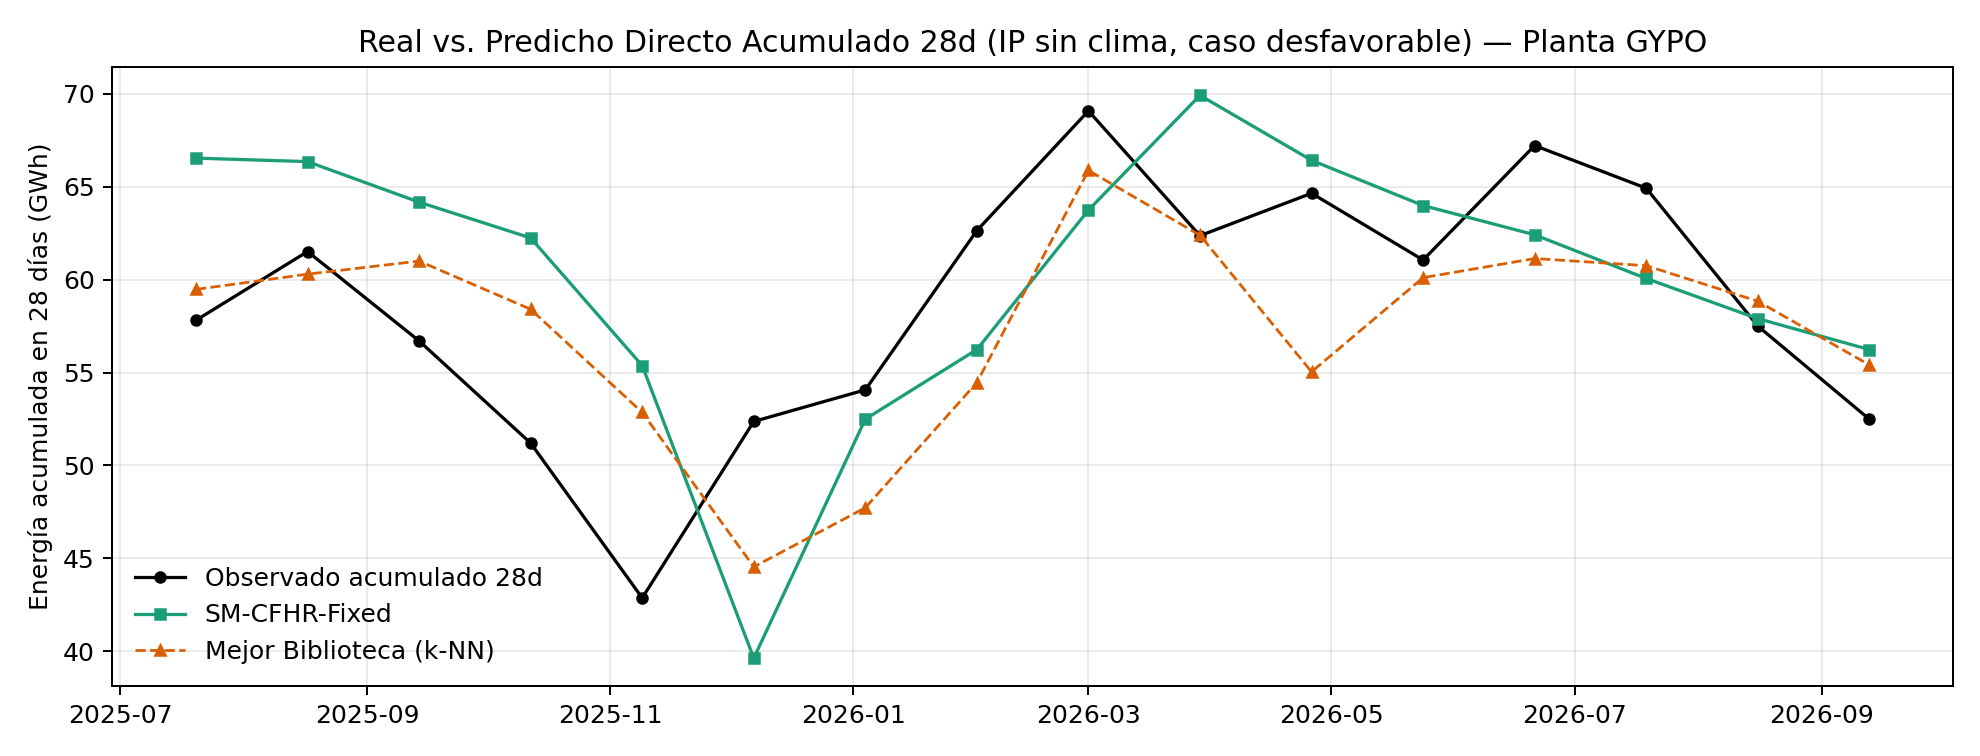

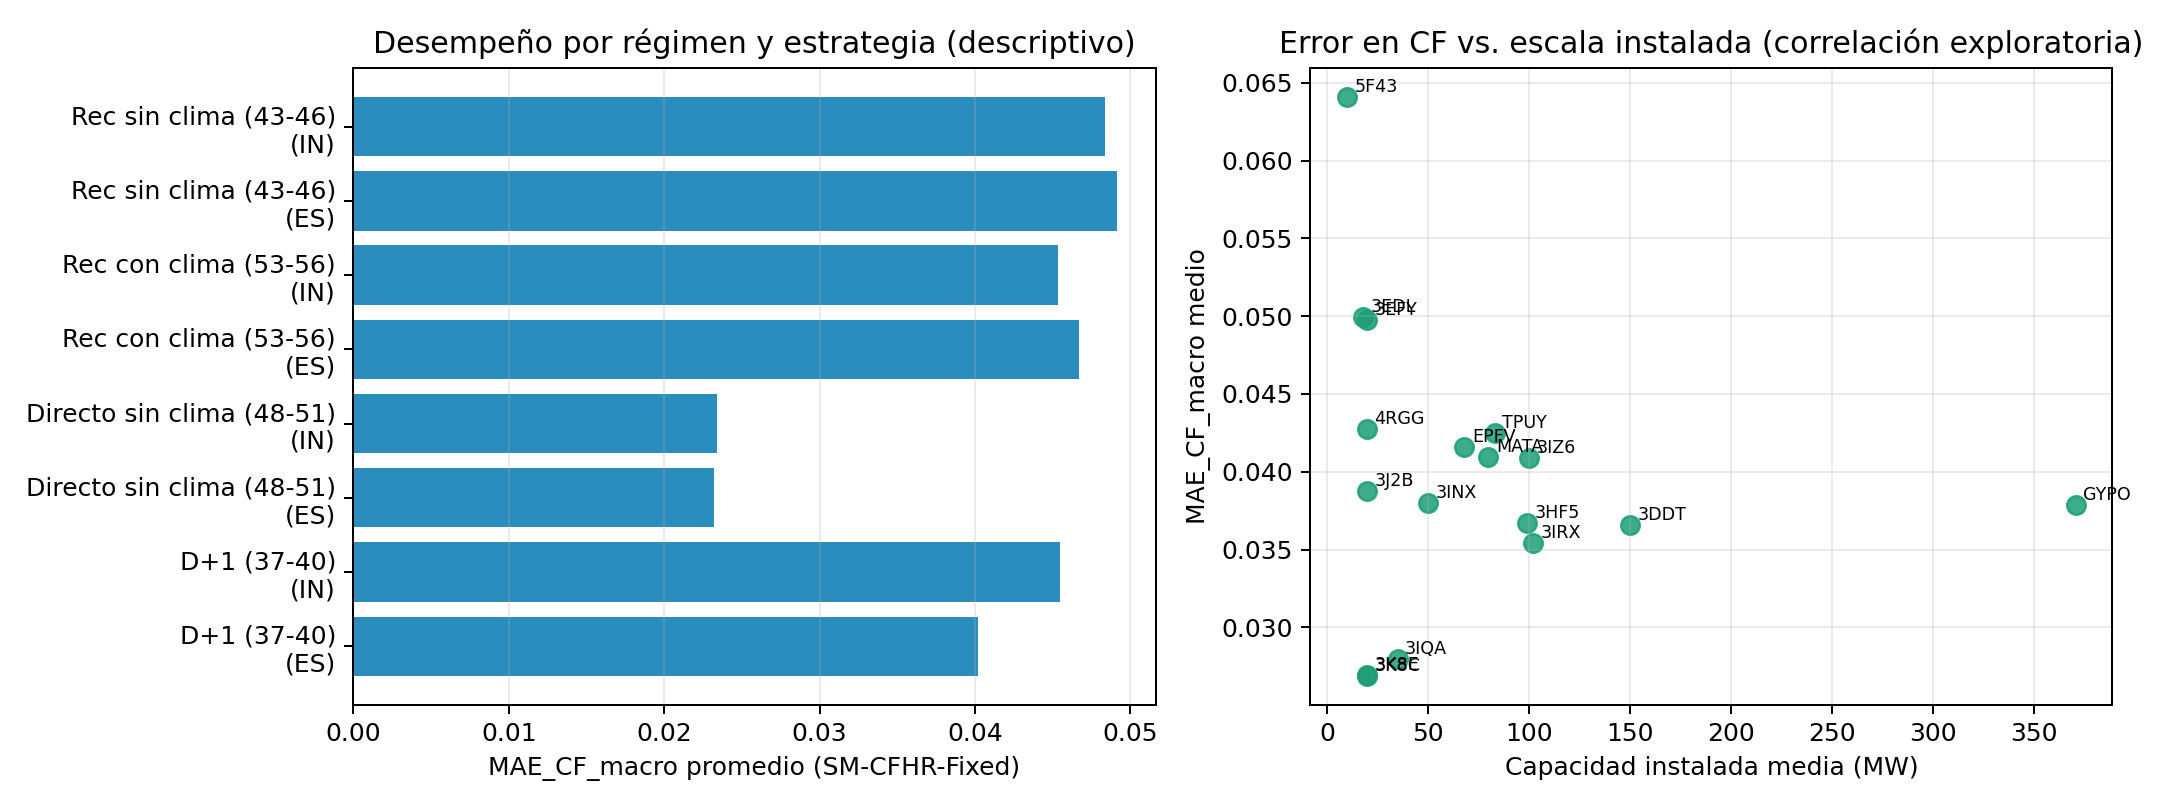

In [4]:
print("Plantas con cambios temporales de capacidad instalada:")
display(cap_chg)

print(f"Cambios de rango kWh vs CF: {(met['cambio_rango_kWh_vs_CF']!=0).sum()}/28 | Rango medio kWh={met['rango_en_23_kWh'].mean():.2f} vs CF={met['rango_en_23_CF'].mean():.2f}")
display(met[[
    "escenario", "rango_en_23_kWh", "rango_en_23_CF",
    "MAE_macro_kWh_Fixed", "MAE_CF_macro_Fixed", "nMAE_rel_generacion_media_planta_Fixed",
    "diff_pct_kWh_vs_MejorBib", "diff_pct_CF_vs_MejorBib", "Skill_RMSE_vs_MM30_pct"
]].head(12))

for fig_name in [
    "real_vs_predicho_d1.png",
    "real_vs_predicho_multihorizonte_rec.png",
    "real_vs_predicho_directo_acumulado.png",
    "factorial_descriptivo_regimenes.png",
]:
    fp = REV_DIR / "06_exploratorio_p2" / fig_name
    if fp.exists():
        display(Image(filename=str(fp)))


## 5. Síntesis de conclusiones verificables

1. **Correspondencia métrica–inferencia:** Con `z_t^macro` y bootstrap sincronizado por bloques temporales, todas las pruebas contrastan el mismo estimando `MAE_macro` que el ranking principal.
2. **Evidencia confirmatoria vs. exploratoria:** La ventaja estadísticamente robusta tras Holm se concentra en **ET + Clima** (`5/28` escenarios sobre `MAE_macro`, todos con $T_{\mathrm{eff}} \ge 30.82$), mientras que en **Intraplanta** y especialmente en **`DirectoSinClima_intraplanta`** SM-CFHR pierde competitividad frente a `k-NN` y `BayesianRidge`.
3. **Transparencia de escala:** Al evaluar en `MAE_CF_macro` adimensional, el desempeño relativo se modera (`16/28` victorias, rango medio `4.00/23`), confirmando que parte de la ventaja en `kWh` proviene del peso de las centrales de mayor capacidad en la cohorte.
